- Here in this chapter we will learn about the training and evalution of models.

  ![1. Pretraining flow](../images/1.pretrainingflow.png)

 # Weight parameters

- In the context of LLMs and other deep learning models, weights refer to the trainable parameters that the learning process adjusts. These weights are also known asweight parameters or simply parameters.

- In frameworks like PyTorch, these `weights are stored in linear layers`.

-  After initializing a layer in multiheadattention (new_layer= torch.nn.Linear(...)), we can access its weights through the .weight attribute, new_layer.weight.

-  Additionally, for convenience, PyTorch allows direct access to all a model’s trainable parameters, including weights and biases, through
the method model.parameters(), which we will use later when implementing the model training.

# evaluting generative text models

- Previously we have generated texts using the model. now we need to evalute the training and validation of those generated texts.

- Here is the flow how the texts are evaluted in this phase.


  ![2. Evalution flow](../images/2.evalutionflow.png)

## Using GPT to generate text

In [67]:
from gpt import GPTModel
import torch
GPT_CONFIG_124M = {
 "vocab_size": 50257,
 "context_length": 256,
 "emb_dim": 768,
 "n_heads": 12,
 "n_layers": 12,
 "drop_rate": 0.1,
 "qkv_bias": False
}
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)

In [68]:
def generate_text_simple(model, idx, max_new_tokens, context_size):
    # idx is to fetch the batch of the tokens.

    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        
        #Crops current context if it exceeds the supported context size, e.g., if LLM supports only 5 tokens, and the context size is 10, Ωthen only the last 5 tokens are used as context
        with torch.no_grad():
            logits = model(idx_cond)

        #Focuses only on the last time step, so that (batch, n_token, vocab_size) becomes (batch, vocab_size)
        logits = logits[:, -1, :] 
        
        # probas has shape (batch, vocab_size).
        probs = torch.softmax(logits, dim=-1)

        # argmax returns the index of the tensor with the max_value
        idx_next = torch.argmax(probs, dim=-1, keepdim=True)

        # appending the last index to input
        idx = torch.cat((idx, idx_next), dim=1)
        
    return idx

- There are 3 steps are involved between between textual input to output.

- First,the tokenizer converts input text into a series of token IDs .

- Second, the model receives these token IDs and generates corresponding logits, which are vectors representing the probability distribution for each token in the vocabulary.

- Third, these logits are converted back into token IDs, which the tokenizer decodes into human-readable text, completing the cycle from textual input to textual output.

In [69]:
import tiktoken

def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text)
    encoded_tensor = torch.tensor(encoded).unsqueeze(0) # converted into batches
    return encoded_tensor


def token_ids_to_text(token_ids, tokenizer):
    ids = token_ids.squeeze(0) # removes the batch
    return tokenizer.decode(ids.tolist())


# give tokens to the model as the input
start_context="Every effort moves you"
tokenizer = tiktoken.get_encoding("gpt2")

#final token_ids
token_ids = generate_text_simple(
    model, idx = text_to_token_ids(start_context, tokenizer),
    max_new_tokens=10, context_size=GPT_CONFIG_124M["context_length"]
)

output = token_ids_to_text(token_ids, tokenizer)

print("Output text:\n", output)

    

Output text:
 Every effort moves you compulsory Certain downstairscol confid stairs Twistyu smuggling*,


- still it is not producing the cohrent text, so we need to implement numerical method to evalute the generated content.

- This approach will enable us to monitor and enhance the model’s performance throughout its training process.

- After text generation we need to find the loss, because that is the main indicator using it only we need find the correct weights by decreasing the loss.

## Calculating the text generation loss
- we need to calculate the text generation loss during the entire training.

![3. textgen flow](../images/3.textgenflow.png)

- using the above 5 steps the gpts initially they predicts the next tokens.

- Here now i am giving two inputs along with thier targetted outputs.

In [70]:
inputs = torch.tensor([[16833, 3626, 6100], # ["every effort moves",
 [40, 1107, 588]]) # "I really like"]

targets = torch.tensor([[3626, 6100, 345 ], # [" effort moves you",
 [1107, 588, 11311]]) # " really like chocolate"]


- now feed these inputs to the model and find the logits in the output layer.

In [71]:
with torch.no_grad(): #disabling gradients because we are not training currently.
    logits = model(inputs)

probs = torch.softmax(logits, dim=-1)
print(probs.shape)

torch.Size([2, 3, 50257])


- now find the highest prob of each token from their row vectors.

In [72]:
token_ids = torch.argmax(probs, dim=-1, keepdim=True)
print("Token IDs:\n", token_ids) # got the highest prob token for each vector.

Token IDs:
 tensor([[[27797],
         [37447],
         [27147]],

        [[17375],
         [18121],
         [13195]]])


- those above are for two batches, now convert those tokens back into the text.

In [73]:
print(f"Targets batch 1: {token_ids_to_text(targets[0], tokenizer)}")
print(f"Outputs batch 1:"
 f" {token_ids_to_text(token_ids[0].flatten(), tokenizer)}")

Targets batch 1:  effort moves you
Outputs batch 1:  NumbersAlready CBD


- The model produces random text that is different from the target text because it hasnot been trained yet. We now want to evaluate the performance of the model’s generated text numerically via a loss.

- This improves model's performace to generate the text.

- Now we need to find how far the model generated text and output targets, and also using it we can adjust weights and trying to make model predict more similar text to the actual output.

- the `model training main aim is to increase the softmax probabilities of the correct output in the token vector`. the higher the probability in the correct positions, the better is the text correct.

- now we need to print what actually we got in the softmax probs for the acutal target ids.

In [74]:
text_idx = 0
print(probs.shape)
target_probs_1 = probs[text_idx, [0, 1, 2], targets[text_idx]]
print(target_probs_1)

text_idx = 1
target_probs_2 = probs[text_idx, [0, 1, 2], targets[text_idx]]
print(target_probs_2)

torch.Size([2, 3, 50257])
tensor([1.0179e-05, 1.1120e-06, 2.9709e-06])
tensor([3.3252e-07, 1.9829e-06, 1.0266e-08])


- now we need to increase the prob of this actual targets from current prob values.

# Backpropagation
- `How do we maximize the softmax probability values corresponding to the target tokens?`

- The big picture is that we update the model weights so that the model outputs higher values for the respective token IDs we want to generate. The weight update is
done via a process called backpropagation.

- a standard technique for training deep neural networks.

- Backpropagation requires a loss function, which calculates the difference between the model’s predicted output and the actual desired output. This loss function measures how far off the model’s predictions are from the target values.


![4. loss calculation flow](../images/4.errorflow.png)

- from here we already done the 1-3 steps.

- now need log of the target probs we got.

In [75]:
target_probs_1.shape, target_probs_2.shape
log_probs = torch.log(torch.cat((target_probs_1, target_probs_2))) # cat takes a tuple as an input
log_probs


tensor([-11.4952, -13.7094, -12.7267, -14.9166, -13.1309, -18.3945])

- Working with logarithms of probability scores is more manageable in mathematical optimization than handling the scores directly.

- we combine these log probabilities into a single score by computing the average - step:5

In [76]:
avg_log_probs = torch.mean(log_probs)
avg_log_probs 

tensor(-14.0622)

- `The goal is to get the average log probability as close to 0 as possible by updating the model’s weights as part of the training process`.

- However, in deep learning, the common practice isn’t to push the average log probability up to 0 but rather to bring the negative average log probability down to 0. The negative average log probability is simply the average log probability multiplied by –1, which corresponds to step 6.

In [77]:
neg_avg_log_probs = avg_log_probs * -1
print(neg_avg_log_probs)

tensor(14.0622)


- In deep learning, the term for turning this negative value, –13.7637, into 13.7637, is known as the `cross entropy loss`.

- pytorch has an inbuilt function to calculate this cross entropy loss.

## cross entropy loss

- At its core, the cross entropy loss is a popular measure in machine learning and deep learning that measures the difference between two probability distributions—typically, the true distribution of labels (here, tokens in a dataset) and the predicted distribution from a model (for instance, the token probabilities generated by an LLM).

- when we want to apply the cross entropy function, we using the torch we need look again how the shapes are.

In [78]:
logits.shape, targets.shape

(torch.Size([2, 3, 50257]), torch.Size([2, 3]))

- we need to flatten these to apply the cross entropy.

In [79]:
logits_flat = logits.flatten(0, 1) # batch and tokens are flatten
targets_flat = targets.flatten(0, 1) # batches and toekns are flatten
logits_flat.shape, targets_flat.shape

(torch.Size([6, 50257]), torch.Size([6]))

In [80]:
# we can apply cross entropy on it.
loss = torch.nn.functional.cross_entropy(logits_flat, targets_flat)
loss

tensor(14.0622)

# perplexity
- it also a measure like cross entropy that uses to evalute the performace of a models in tasks like langauge modelling.

- it can provide a more interpretable way to understand the uncertainty of a model in predicting the next token in a sequence.

- Perplexity measures how well the probability distribution predicted by the model matches the actual distribution of the words in the dataset. Similar to the loss, a lower perplexity indicates that the model predictions are closer to the actual distribution.

- We have now calculated the loss for two small text inputs for illustration purposes. Next, we will apply the loss computation to the entire training and validation sets.

## Calculating the training and validation set losses
- `first we must prepare the training and validation dataset to train the LLM.`

- Apply the loss to the entire dataset, which we split into a training and validation portion.

- We are taking the old verdict.txt for the data set.

In [81]:
file_path = "verdict.txt"
with open(file_path, "r", encoding="utf-8") as file:
    text_data = file.read()
text_data

'I HAD always thought Jack Gisburn rather a cheap genius--\nthough a good fellow enough--so it was no great surprise to\nme to hear that, in the height of his glory, he had dropped\nhis painting, married a rich widow, and established himself\nin a villa on the Riviera. (Though I rather thought it would\nhave been Rome or Florence.)\n"The height of his glory"--that was what the women called\nit. I can hear Mrs. Gideon Thwing--his last Chicago sitter--\ndeploring his unaccountable abdication. "Of course it\'s\ngoing to send the value of my picture \'way up; but I don\'t\nthink of that, Mr. Rickham--the loss to Arrt is all I think of."\nThe word, on Mrs. Thwing\'s lips, multiplied its _rs_ as\nthough they were reflected in an endless vista of mirrors.\nAnd it was not only the Mrs. Thwings who mourned. Had\nnot the exquisite Hermia Croft, at the last Grafton Gallery\nshow, stopped me before Gisburn\'s "Moon-dancers" to say,\nwith tears in her eyes: "We shall not look upon its like\nagain"?

In [82]:
total_characters = len(text_data)
total_tokens = len(tokenizer.encode(text_data))
print(f"total characters {total_characters}")
print(f"total_tokens {total_tokens}")

total characters 20663
total_tokens 5516


![4. Training data flow](../images/5.trainingdataflow.png)

- to implement data splitting and loading, we first define a train ratio to use 90% data to train and remaining 10% of data to validation during model training.

In [83]:
train_ratio = 0.9
split_index = int(len(text_data) * train_ratio)
train_data = text_data[:split_index]
val_data = text_data[split_index:]

In [84]:
from torch.utils.data import Dataset, DataLoader 
def create_dataloader_v1(txt, max_length=256, stride=128, batch_size=4,shuffle=True, drop_last=True, num_workers=0):
    tokenizer = tiktoken.get_encoding("gpt2")
    dataset = GPTDatasetV1(txt, tokenizer, stride, max_length)
    dataloader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=shuffle,
    drop_last=drop_last,     #drop_last=True drops the last batch if it is shorter than the specified batch_size to prevent loss spikes during training
    num_workers=num_workers # no of cpu processes to use for preprocessing
    )

    return dataloader


class GPTDatasetV1(Dataset):
    def __init__(self, text, tokenizer, stride, max_length):
        self.input_ids=[]
        self.target_ids=[]

        token_ids = tokenizer.encode(text)
        # from these token ids create input ids and thier targets.

        for i in range(0, len(token_ids)-max_length, stride):
            input_chunk  = token_ids[i: i+max_length] # at a time taking maxlength of inputs and thier target not a single
            target_chunk = token_ids[i+1: i+max_length+1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids) # returns all rows in the dataset

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx] #Returns a single row from the dataset
    

In [85]:
# from gpt import create_dataloader_v1

train_dataloader = create_dataloader_v1(
    train_data, 
    GPT_CONFIG_124M["context_length"], 
    stride= GPT_CONFIG_124M["context_length"],
    batch_size=2,
    shuffle=True,
    drop_last=True,
    num_workers=0
)

val_dataloader = create_dataloader_v1(
    val_data, 
    GPT_CONFIG_124M["context_length"], 
    stride= GPT_CONFIG_124M["context_length"],
    batch_size=2,
    shuffle=False,
    drop_last=False,
    num_workers=0
)

- we are currently using the very small batch numbers, relative to LLMs they are like 1024 is not uncommon. As an optional check, we can iterate through the data loaders to ensure that they were created correctly:

In [86]:
print("trained dataset")
for x, y in train_dataloader:
    print(x.shape, y.shape)
    
print("validated dataset")
for x, y in val_dataloader:
    print(x.shape, y.shape)

trained dataset
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
validated dataset
torch.Size([2, 256]) torch.Size([2, 256])


- now we have 9 training set samples and 1 validation set.

- we know that the targets are the just shifting of the next token in the input, but the inputs are in the batches of the size, batch*no of tokens in it. so make thier both shapes similar to find the loss.

In [101]:
def calc_loss_batch (input_batch, target_batch, model, device):
    # device used for,  The transfer to a given device allows us to transfer the data to a GPU.
    input_batch = input_batch.to(device)
    target_batch = target_batch.to(device)
    
    logits = model(input_batch)
    loss = torch.nn.functional.cross_entropy(logits.flatten(0, 1), target_batch.flatten())
    return loss
    

- using the above function, we only can generate the loss for the single batch, we need to find the loss for the all the batches, so we need to use the dataloader class.

  #  Function to compute the training and validation loss

In [88]:
def calc_loss_loader (data_loader, model, device, num_batches=None):
    total_loss=0
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader) # iterate over all batches if no fixed num_batches are specified
    else:
        num_batches = min(num_batches, len(data_loader)) # Reduces the number of batches to match the total number of batches in the data loader if num_batches exceeds the number of batches in the data loader

    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i< num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss
        else:
            break
            
    return total_loss/num_batches #average loss over all batches



In [89]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

with torch.no_grad(): 
    train_loss = calc_loss_loader(train_dataloader, model, device)
    val_loss = calc_loss_loader(val_dataloader, model, device)

print("Training loss:", train_loss)
print("Validation loss:", val_loss)


Training loss: tensor(11.6748)
Validation loss: tensor(11.8006)


- the best way to make model generate the text like human by decreasing the loss 0 , by training the model. that is the current step.

# Training an LLM


![7. Training loop](../images/7.trainingloop.png)

- These are main steps involved in the training loop, It outlines eight steps, starting with iterating over each epoch, processing batches, resetting gradients, calculating the loss and new gradients, and updating weights and concluding with monitoring steps like printing
losses and generating text samples.

# The main function for pretraining LLMs

In [103]:
def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs, eval_freq, eval_iter, start_context, tokenizer):
    #initialises list to track the loss and tokens
    train_losses, val_losses, track_tokens_seen = [], [], []
    
    tokens_seen, global_step = 0, -1

    for epoch in range(num_epochs): #starts the main training loop
        model.train()
        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()
            # find loss
            loss = calc_loss_batch(input_batch, target_batch, model, device)

            # calculate the loss gradients
            loss.backward()

            # update the model weights using loss gradients
            optimizer.step()
            tokens_seen += input_batch.numel()
            global_step += 1

            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter
                )
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                f"Train loss {train_loss:.3f}, "
                f"Val loss {val_loss:.3f}"
                )

        # prints sample text after every epoch
        generate_and_print_sample(model, tokenizer, device, start_context)
        
    return train_losses, val_losses, track_tokens_seen
    

In [91]:
def evaluate_model(model, train_lader, val_loader, device, eval_iter):
    model.eval() #dropout disabled while evalution for the stable, reproducible results.
    
    with torch.no_grad(): #Disables gradient tracking, which is not required during evaluation, to reduce the computational overhead
        train_loss = calc_loss_loader(train_dataloader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_dataloader, model, device, num_batches=eval_iter)
        
    model.train()
    return train_loss, val_loss
        

In [94]:
def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    
    with torch.no_grad():
        token_ids = generate_text_simple(
        model=model, idx=encoded,
        max_new_tokens=50, context_size=context_size)
    
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))
    
    model.train()
    

- Adam W, optimizer using in the neural networks for training. . However, in our training loop, we opt for the AdamW optimizer. AdamW is a variant of Adam that improves the weight decay approach, which aims to minimize model complexity and prevent overfitting by penalizing larger weights. This adjustment allows AdamW to achieve more effective regularization and better generalization; thus, AdamW is frequently used in the training of LLMs.


In [106]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.to(device)
# how does this learning rate and weight decay impacts the weights based on the loss we calculated and how it updates?
optimizer = torch.optim.AdamW(
 model.parameters(),
 lr=0.0004, weight_decay=0.1
)
num_epochs = 20

train_losses, val_losses, tokens_seen = train_model_simple(
 model, train_dataloader, val_dataloader, optimizer, device,
 num_epochs=num_epochs, eval_freq=5, eval_iter=5,
 start_context="Every effort moves you", tokenizer=tokenizer
)

Ep 1 (Step 000000): Train loss 47.982, Val loss 48.562
Ep 1 (Step 000005): Train loss 15.750, Val loss 15.900
Every effort moves you to to Britann362 custom to to to to Britann custom to Britann custom to Britann custom to Britann custom to Britann to to Britann Gillespie to Britann to Britann to Britann custom to Britann custom to to to to362 to Britann custom to to Britann custom to to
Ep 2 (Step 000010): Train loss 10.645, Val loss 11.708
Ep 2 (Step 000015): Train loss 7.411, Val loss 8.912
Every effort moves you his his his his" was a--""" was a of his his" of his his of his"" us of his us.". in his." his his glory"""".". of his"; and up""
Ep 3 (Step 000020): Train loss 8.400, Val loss 9.651
Ep 3 (Step 000025): Train loss 7.159, Val loss 8.804
Every effort moves you me--his thedemand the a the the--his painting the by thehound's head between . . . . . . . . . . . . the by the Riv the the's had_'s past the history the's past on by I
Ep 4 (Step 000030): Train loss 5.065, Val loss 7.4

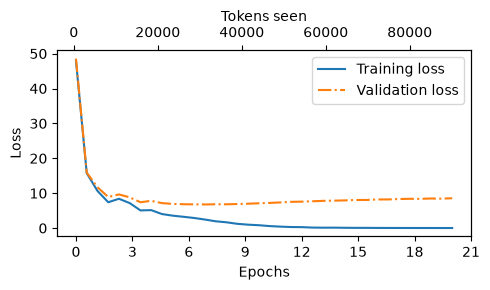

In [107]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
 fig, ax1 = plt.subplots(figsize=(5, 3))
 ax1.plot(epochs_seen, train_losses, label="Training loss")
 ax1.plot(
 epochs_seen, val_losses, linestyle="-.", label="Validation loss"
 )
 ax1.set_xlabel("Epochs")
 ax1.set_ylabel("Loss")
 ax1.legend(loc="upper right")
 ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
 ax2 = ax1.twiny()
 ax2.plot(tokens_seen, train_losses, alpha=0)
 ax2.set_xlabel("Tokens seen")
 fig.tight_layout()
 plt.show()
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

-  At the beginning of the training, both the training and validation set losses sharply decrease, which is a sign that the model is learning. However, the training set loss continues to decrease past the second epoch, whereas the validation loss stagnates. This is a sign that the model is still learning, but it’s overfitting to the training set past epoch 2.